# The Archiver over the 30 minutes before each PM capture

Input: `pm_windows.parquet` and `<event_id>/<family>.parquet` of this folder, written by `ess_pm_archiver_window.py`.
A window runs from `event_ts` minus 30 minutes to `event_ts`. Each section states the question, the data used, and
prints the answer computed from that data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

INK, MUTED, SURFACE, GRID, GREY, CRITICAL = "#1a1a19", "#6b6b66", "#fcfcfb", "#e6e5e0", "#b9b8b0", "#d03b3b"
BLUE, GREEN = "#2a78d6", "#1baf7a"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 100, "display.width", 200)

PERMIT = "FBIS::beam_permit_ok"
# A drop of the beam permit this close before event_ts is the trip of the capture itself. The drops of the 2025
# captures sit 0.3 to 1.3 s before it, the next closest drop is 5.8 s before.
OWN_TRIP_S = 2
windows = pd.read_parquet("pm_windows.parquet").sort_values("event_ts", ignore_index=True)
SECONDS = int(round((windows.event_ts - windows.window_start).dt.total_seconds().iloc[0]))
families = sorted({p.stem for p in Path(".").glob("*/*.parquet") if p.parent.name.isdigit()})
# A run: captures less than a day apart, named by the day of its first capture.
run = (windows.event_ts.diff() > pd.Timedelta(days=1)).cumsum()
windows["run"] = windows.groupby(run).event_ts.transform(lambda t: t.min().strftime("%Y-%m-%d"))
windows["since_previous_pm_s"] = windows.groupby("run").event_ts.diff().dt.total_seconds()
print(f"{len(windows)} captures in {windows.run.nunique()} runs, {SECONDS // 60} min windows, "
      f"{len(families)} families: {', '.join(families)}")

65 captures in 4 runs, 30 min windows, 14 families: CRYO, KLYSTRONS, LLRF, MAGNETS, MODULATORS, MPS, RF_DET_Q_W, RF_PWR_FLD, RF_SHUT, RF_TEMP, SCBCMS, SCBPMS, SCL, VACCUM


## 1. Coverage

**Question.** How much of each 30 minute window has Archiver data?

**Data.** `archiver_from` and `covered_s` of `pm_windows.parquet`: the start of the Archiver folders that run up to
the capture, taken from their samples by `ess_pm_archiver_window.py`. For the samples per second used below:
`seconds_before` of every row with `held == False`, in all 14 family files of a capture.

In [2]:
def per_second(event_id: int, family: str) -> np.ndarray:
    t = pq.read_table(f"{event_id}/{family}.parquet", columns=["seconds_before", "held"]).to_pandas()
    return np.histogram(SECONDS - t.seconds_before[~t.held].to_numpy(), bins=np.arange(SECONDS + 1))[0]


# counts[capture, family, second]; second 0 is the start of the window, second SECONDS - 1 ends at the capture.
counts = np.stack([np.stack([per_second(e, f) for f in families]) for e in windows.event_id])
from_s = ((windows.archiver_from - windows.window_start).dt.total_seconds().clip(lower=0)).to_numpy()
covered = np.arange(SECONDS)[None, :] >= from_s[:, None]
windows["covered_min"] = covered.sum(axis=1) / 60
full = windows.covered_min >= (SECONDS - 1) / 60
short = windows[~full]
print(f"Answer. {full.sum()} of {len(windows)} windows are covered for all {SECONDS // 60} minutes. "
      f"{len(short)} are not: " + ", ".join(f"{r.event_id} ({r.event_ts:%Y-%m-%d %H:%M} UTC, {r.covered_min:.1f} min)"
                                            for r in short.itertuples()) + ".")
windows.groupby("run").covered_min.describe()[["count", "min", "50%", "max"]].round(1)

Answer. 58 of 65 windows are covered for all 30 minutes. 7 are not: 15642507892 (2025-05-28 20:45 UTC, 0.1 min), 15642513562 (2025-05-28 20:51 UTC, 6.9 min), 15642516376 (2025-05-28 20:55 UTC, 10.2 min), 15642519638 (2025-05-28 20:59 UTC, 14.1 min), 15642520842 (2025-05-28 21:00 UTC, 15.6 min), 15642522046 (2025-05-28 21:01 UTC, 17.0 min), 15642523474 (2025-05-28 21:03 UTC, 18.7 min).


,count,min,50%,max
run,,,,
2025-05-28,31.0,0.1,30.0,30.0
2026-06-08,3.0,30.0,30.0,30.0
2026-06-10,2.0,30.0,30.0,30.0
2026-06-28,29.0,30.0,30.0,30.0


## 2. Earlier trips inside the window

**Question.** How many windows hold an earlier trip, so that their 30 minutes are not 30 minutes of beam?

**Data.** (a) `event_ts` of the PM captures, from `pm_windows.parquet`: time from the previous capture of the same
run. (b) `FBIS::beam_permit_ok` in `MPS.parquet`: each change from 1 to 0 with `held == False` is a drop of the beam
permit. A drop in the last 2 s before `event_ts` is the trip of the capture itself; the others are earlier trips.

In [3]:
def on_seconds(d: pd.DataFrame, window_start: pd.Timestamp) -> np.ndarray:
    """A step series (a value holds until the next sample) read at each second of the window."""
    grid = window_start.value + np.arange(SECONDS) * 1_000_000_000
    i = np.searchsorted(d.ts.astype("int64").to_numpy(), grid, side="right") - 1
    return np.where(i >= 0, d.value.to_numpy()[np.clip(i, 0, None)], np.nan)


permit, beam, own, drops_in, last_drop = [], [], [], [], []
bcm = pd.read_parquet(f"{windows.event_id[0]}/SCBCMS.parquet", columns=["pv"])
BEAM_PV = sorted(pv for pv in bcm.pv.unique() if pv.startswith("MEBT") and "FlatTopCurrent" in pv)[0]
for w in windows.itertuples():
    p = pd.read_parquet(f"{w.event_id}/MPS.parquet").query("pv == @PERMIT").sort_values("ts")
    permit.append(on_seconds(p, w.window_start))
    before = p.seconds_before[(p.value == 0) & (p.value.shift() == 1) & ~p.held]
    own.append(bool((before <= OWN_TRIP_S).any()))
    earlier = before[before > OWN_TRIP_S]
    drops_in.append(len(earlier))
    last_drop.append(earlier.min() if len(earlier) else np.nan)
    b = pd.read_parquet(f"{w.event_id}/SCBCMS.parquet").query("pv == @BEAM_PV").sort_values("ts")
    beam.append(on_seconds(b, w.window_start))
permit, beam = np.array(permit), np.array(beam)
windows["own_drop_in_window"] = own
windows["earlier_drops"] = drops_in
windows["last_earlier_drop_min_before"] = np.array(last_drop) / 60

near = windows.since_previous_pm_s < SECONDS
print(f"Answer. (a) {near.sum()} of {windows.since_previous_pm_s.notna().sum()} captures with a previous capture in "
      f"their run come less than {SECONDS // 60} min after it (median {windows.since_previous_pm_s.median() / 60:.0f} min). "
      f"(b) {(windows.earlier_drops > 0).sum()} of {len(windows)} windows hold at least one earlier drop of the beam "
      f"permit, {windows.earlier_drops.sum()} in all. The drop of the capture itself is in the window for "
      f"{windows.own_drop_in_window.sum()} captures, all from "
      f"{', '.join(windows.run[windows.own_drop_in_window].str[:4].unique())}; the other "
      f"{(~windows.own_drop_in_window).sum()} have no drop in the last {OWN_TRIP_S} s before event_ts.")
windows.groupby("run").agg(captures=("event_id", "size"),
                           previous_capture_within_30_min=("since_previous_pm_s", lambda s: int((s < SECONDS).sum())),
                           windows_with_an_earlier_drop=("earlier_drops", lambda s: int((s > 0).sum())),
                           earlier_drops=("earlier_drops", "sum"),
                           own_drop_in_window=("own_drop_in_window", "sum"))

Answer. (a) 37 of 61 captures with a previous capture in their run come less than 30 min after it (median 21 min). (b) 43 of 65 windows hold at least one earlier drop of the beam permit, 102 in all. The drop of the capture itself is in the window for 26 captures, all from 2025; the other 39 have no drop in the last 2 s before event_ts.


,captures,previous_capture_within_30_min,windows_with_an_earlier_drop,earlier_drops,own_drop_in_window
run,,,,,
2025-05-28,31,18,17,36,26
2026-06-08,3,1,1,3,0
2026-06-10,2,0,0,0,0
2026-06-28,29,18,25,63,0


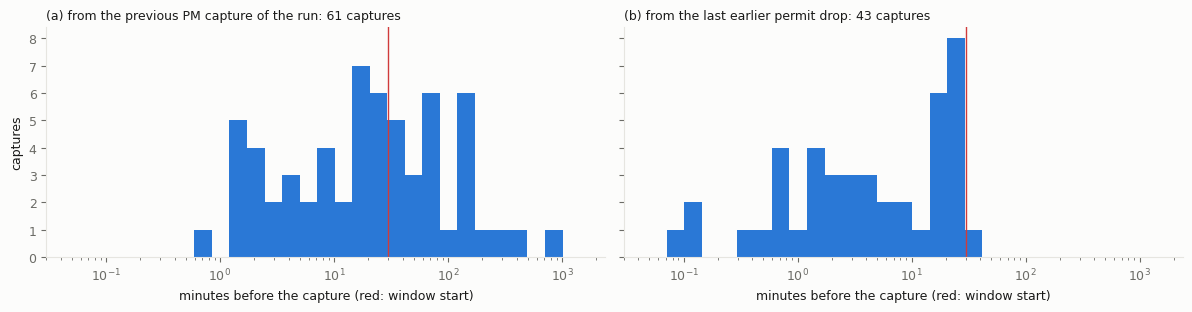

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
bins = np.logspace(np.log10(0.05), np.log10(24 * 60), 30)
for ax, minutes, title in zip(axes, [windows.since_previous_pm_s / 60, windows.last_earlier_drop_min_before],
                              ["(a) from the previous PM capture of the run", "(b) from the last earlier permit drop"]):
    m = minutes.dropna()
    ax.hist(m.clip(upper=bins[-1]), bins=bins, color=BLUE)
    ax.axvline(SECONDS / 60, color=CRITICAL, lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("minutes before the capture (red: window start)")
    ax.set_title(f"{title}: {len(m)} captures", loc="left", fontsize=9)
axes[0].set_ylabel("captures")
fig.tight_layout()

## 3. Beam permit and beam current over the window

**Question.** Over the 30 minutes, when is the beam permit held and how much beam is there?

**Data.** `FBIS::beam_permit_ok` (`MPS.parquet`) and the first MEBT beam current monitor, `FlatTopCurrentR`
(`SCBCMS.parquet`), both with their held row, read at every second. Rows are captures in time order. Grey: second
without Archiver data (section 1).

Answer. Beam current monitor: MEBT-010:PBI-BCM-001:FlatTopCurrentR. The beam permit is held for a median 90% of the covered seconds of a window; 18 of 65 windows hold it for more than 99 %.


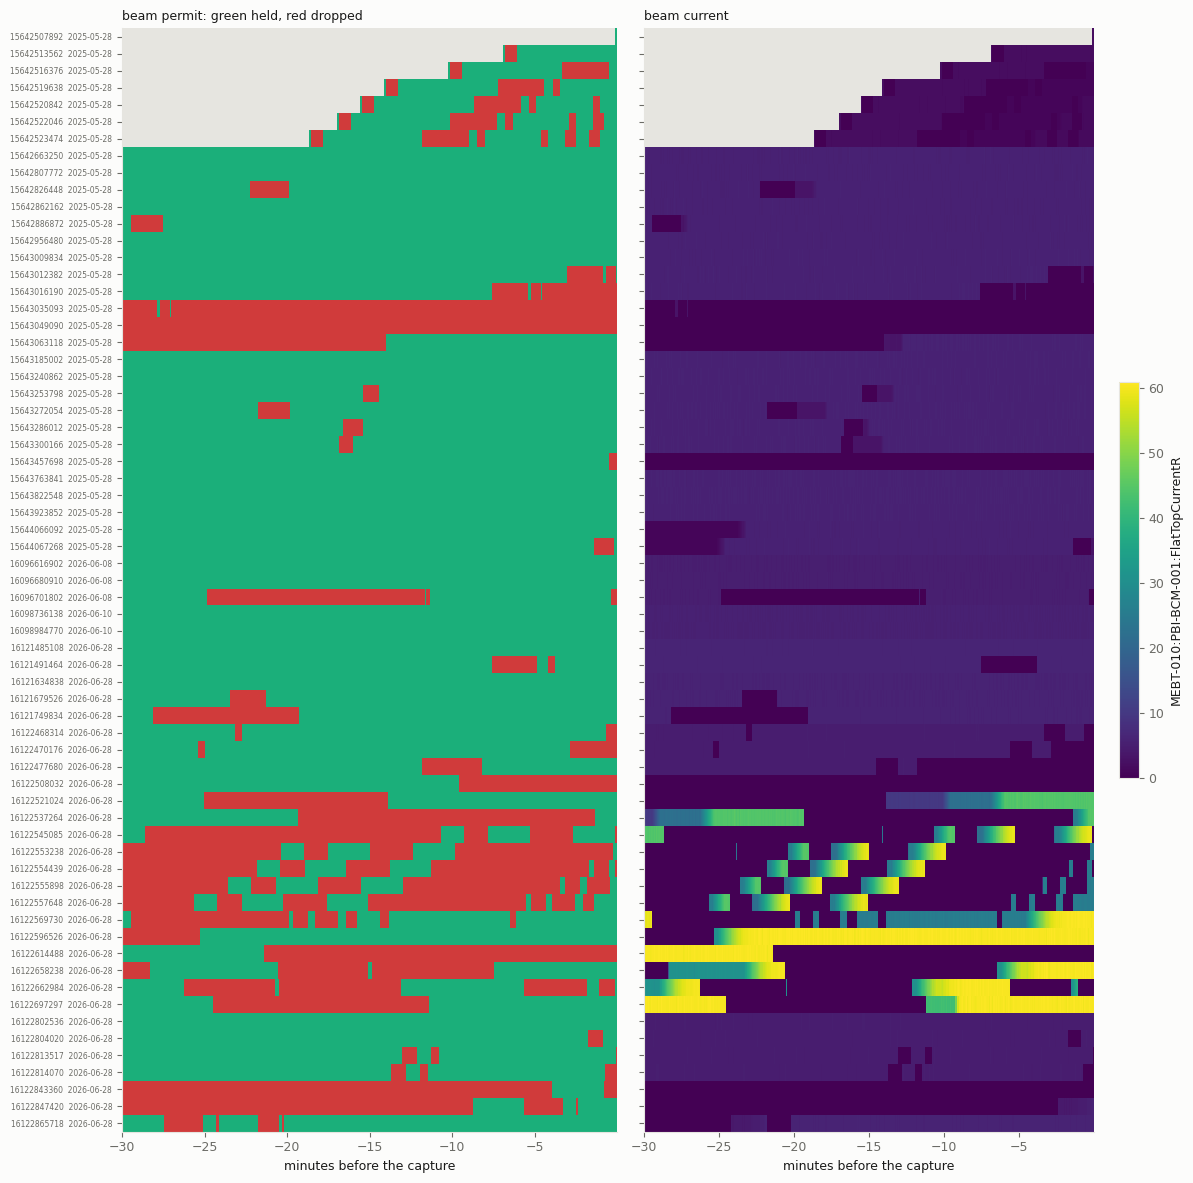

In [5]:
windows["permit_ok_share"] = np.nanmean(np.where(covered, permit == 1, np.nan), axis=1)
print(f"Answer. Beam current monitor: {BEAM_PV}. The beam permit is held for a median "
      f"{windows.permit_ok_share.median():.0%} of the covered seconds of a window; "
      f"{(windows.permit_ok_share > 0.99).sum()} of {len(windows)} windows hold it for more than 99 %.")

x = np.arange(SECONDS) / 60 - SECONDS / 60
fig, axes = plt.subplots(1, 2, figsize=(12, 0.16 * len(windows) + 1.5), sharey=True)
cmap = plt.matplotlib.colors.ListedColormap([CRITICAL, GREEN])
cmap.set_bad(GRID)
axes[0].pcolormesh(x, np.arange(len(windows)), np.ma.masked_invalid(np.where(covered, permit, np.nan)), cmap=cmap,
                   vmin=0, vmax=1, shading="nearest")
axes[0].set_title("beam permit: green held, red dropped", loc="left", fontsize=9)
cmap_b = plt.get_cmap("viridis").copy()
cmap_b.set_bad(GRID)
im = axes[1].pcolormesh(x, np.arange(len(windows)), np.ma.masked_invalid(np.where(covered, beam, np.nan)),
                        cmap=cmap_b, shading="nearest")
fig.colorbar(im, ax=axes[1], label=BEAM_PV, fraction=0.04)
axes[1].set_title("beam current", loc="left", fontsize=9)
for ax in axes:
    ax.set_xlabel("minutes before the capture")
axes[0].set_yticks(range(len(windows)), windows.event_id.astype(str) + "  " + windows.run, fontsize=5.5)
axes[0].invert_yaxis()
fig.tight_layout()

## 4. Samples per family

**Question.** Which families give data all through the window, and which store a value only now and then?

**Data.** The counts of section 1, per family and minute of the window, over the covered minutes of all captures
(a minute is covered when one of its seconds is, section 1).

In [6]:
per_minute = counts.reshape(len(windows), len(families), SECONDS // 60, 60).sum(axis=3)
minute_covered = covered.reshape(len(windows), SECONDS // 60, 60).any(axis=2)
table = pd.DataFrame({
    "pvs": [len({pv for e in windows.event_id
                 for pv in pq.read_table(f"{e}/{f}.parquet", columns=["pv"]).column("pv").unique().to_pylist()})
            for f in families],
    "samples": counts.sum(axis=(0, 2)),
    "samples_per_capture_median": np.median(counts.sum(axis=2), axis=0).astype(int),
    "minutes_without_sample_share": (per_minute == 0).transpose(1, 0, 2)[:, minute_covered].mean(axis=1).round(3)},
    index=families)
quiet = table.index[table.minutes_without_sample_share > 0.5]
print(f"Answer. {(table.minutes_without_sample_share == 0).sum()} of {len(families)} families have a sample in every "
      f"covered minute of every window. More than half of the minutes are without a sample in: {', '.join(quiet) or 'none'}.")
table

Answer. 10 of 14 families have a sample in every covered minute of every window. More than half of the minutes are without a sample in: MPS, RF_SHUT.


,pvs,samples,samples_per_capture_median,minutes_without_sample_share
CRYO,68,12867273,272347,0.000
KLYSTRONS,62,16140931,236565,0.000
LLRF,438,41091659,677980,0.000
MAGNETS,932,47661606,780234,0.000
MODULATORS,80,21675185,354081,0.000
MPS,22,615,6,0.841
RF_DET_Q_W,273,19104433,323983,0.000
RF_PWR_FLD,279,21854361,348718,0.000
RF_SHUT,88,0,0,1.000
RF_TEMP,97,18779692,91171,0.000


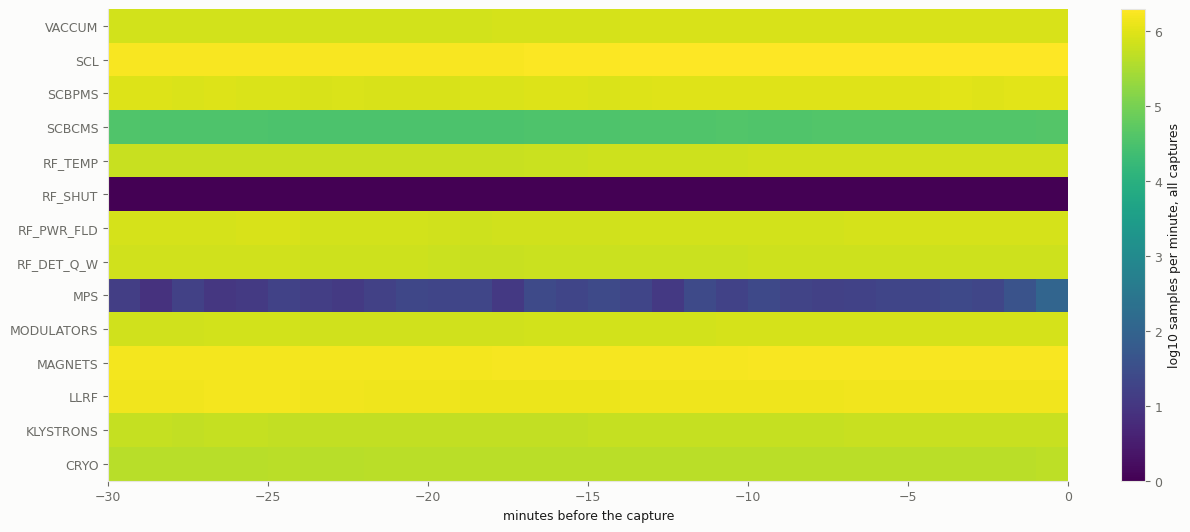

In [7]:
minutes = np.arange(SECONDS // 60) - SECONDS // 60 + 0.5
fig, ax = plt.subplots(figsize=(12, 0.3 * len(families) + 1.2))
im = ax.pcolormesh(minutes, np.arange(len(families)), np.log10(per_minute.sum(axis=0) + 1), cmap="viridis",
                   shading="nearest")
ax.set_yticks(range(len(families)), families)
ax.set_xlabel("minutes before the capture")
fig.colorbar(im, ax=ax, label="log10 samples per minute, all captures", fraction=0.04)
fig.tight_layout()

## Per capture

In [8]:
windows[["event_id", "event_ts", "run", "covered_min", "since_previous_pm_s", "own_drop_in_window", "earlier_drops",
         "last_earlier_drop_min_before", "permit_ok_share", "pvs", "pvs_changing", "rows"]].round(2)

,event_id,event_ts,run,covered_min,since_previous_pm_s,own_drop_in_window,earlier_drops,last_earlier_drop_min_before,permit_ok_share,pvs,pvs_changing,rows
0,15642507892,2025-05-28 20:45:07.983413760+00:00,2025-05-28,0.13,NaN,True,0,NaN,0.88,3340,2611,28450
1,15642513562,2025-05-28 20:51:52.987667968+00:00,2025-05-28,6.88,405.00,True,1,6.77,0.89,3340,2611,1298610
2,15642516376,2025-05-28 20:55:13.984815104+00:00,2025-05-28,10.23,201.00,True,2,3.35,0.65,3340,2610,1877024
3,15642519638,2025-05-28 20:59:06.984389376+00:00,2025-05-28,14.12,233.00,True,3,3.90,0.71,3340,2612,2610188
4,15642520842,2025-05-28 21:00:32.984205056+00:00,2025-05-28,15.55,86.00,True,4,1.45,0.71,3340,2612,2880641
5,15642522046,2025-05-28 21:01:58.985400832+00:00,2025-05-28,16.98,86.00,True,5,1.45,0.70,3340,2612,3143071
6,15642523474,2025-05-28 21:03:40.984174080+00:00,2025-05-28,18.68,102.00,True,6,1.72,0.69,3340,2612,3464775
7,15642663250,2025-05-28 23:50:04.990700800+00:00,2025-05-28,30.00,9984.01,True,0,NaN,1.00,3340,2609,5696828
8,15642807772,2025-05-29 02:42:07.983225856+00:00,2025-05-28,30.00,10322.99,True,0,NaN,1.00,3204,2630,5716744
9,15642826448,2025-05-29 03:04:21.984585216+00:00,2025-05-28,30.00,1334.00,True,1,22.25,0.92,3204,2630,5684213
